In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [3]:
small_animals = np.random.normal(loc=[5, 20], scale=[1, 5],
size=(20, 2))
medium_animals = np.random.normal(loc=[50, 80], scale=[10, 15],
size=(20, 2))
large_animals = np.random.normal(loc=[300, 150], scale=[50, 25],
size=(20, 2))
X_animals = pd.DataFrame(np.vstack([small_animals,
medium_animals, large_animals]), columns=['Weight_kg',
'Height_cm'])


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_animals)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_animals.columns)

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model on scaled data
kmeans.fit(X_scaled_df)

# Get cluster labels
labels = kmeans.labels_

# Add cluster labels to original DataFrame
X_animals['Cluster'] = labels

print(X_animals.head(10))

   Weight_kg  Height_cm  Cluster
0   4.541085  17.002086        2
1   6.608614  16.681148        2
2   3.994626  25.827611        2
3   5.974446  17.318919        2
4   4.179591  22.146338        2
5   4.512469  25.077050        2
6   4.467794  27.636054        2
7   5.486692  28.130726        2
8   4.955952  14.367464        2
9   4.768452  17.021856        2


In [7]:

# Get centroids in scaled space
centroids_scaled = kmeans.cluster_centers_

# Convert centroids back to original scale
centroids_original = scaler.inverse_transform(centroids_scaled)



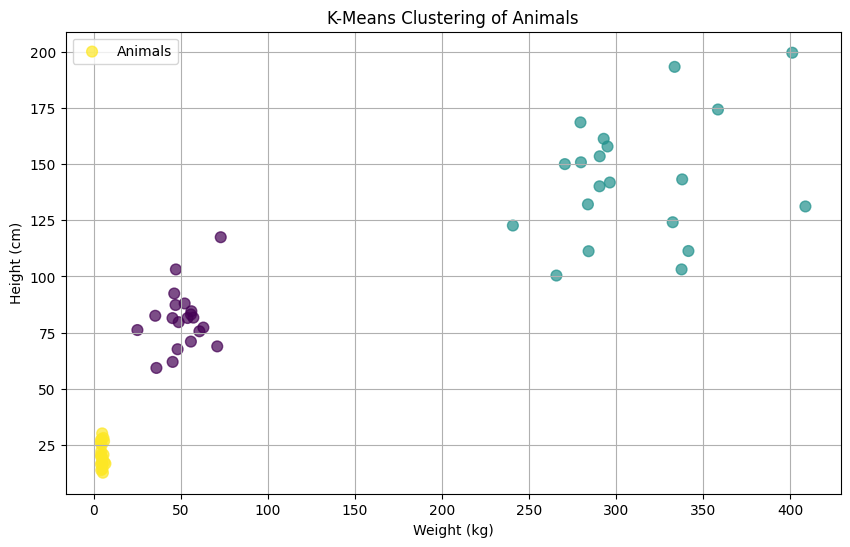

In [10]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_animals['Weight_kg'],
    X_animals['Height_cm'],
    c=X_animals['Cluster'],
    cmap='viridis',
    s=60,
    alpha=0.7,
    label='Animals'
)
plt.xlabel('Weight (kg)')
plt.ylabel('Height (cm)')
plt.title('K-Means Clustering of Animals')
plt.legend()
plt.grid(True)
plt.show()

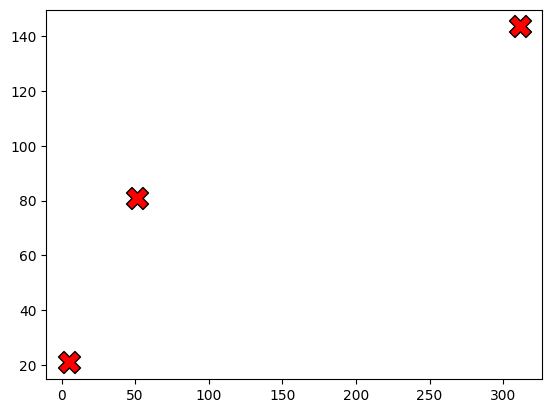

In [13]:
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    color='red',
    marker='X',
    s=250,
    edgecolors='black',
    label='Centroids'
)

In [ ]:
### Activity 2

In [15]:
np.random.seed(42)
# Create synthetic data with some groupings
X_students = pd.DataFrame({
'Study_Hours_Week': np.random.randint(5, 40, 50),
'Sleep_Hours_Night': np.random.uniform(4, 9, 50).round(1)
})
# Add some patterns:
X_students.loc[X_students['Study_Hours_Week'] > 30,
'Sleep_Hours_Night'] = np.random.uniform(4, 6,
sum(X_students['Study_Hours_Week'] > 30)).round(1) # High study,low sleep
X_students.loc[X_students['Study_Hours_Week'] < 10,
'Sleep_Hours_Night'] = np.random.uniform(7, 9,
sum(X_students['Study_Hours_Week'] < 10)).round(1) # Low study,high sleep

In [17]:
# Perform hierarchical clustering using Ward linkage
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
Z = linkage(X_students, method='ward')

print(Z)

[[10.         25.          0.          2.        ]
 [22.         37.          0.1         2.        ]
 [43.         46.          0.1         2.        ]
 [35.         44.          0.2         2.        ]
 [30.         52.          0.28867513  3.        ]
 [ 3.         27.          0.3         2.        ]
 [ 2.         39.          0.3         2.        ]
 [12.         15.          0.4         2.        ]
 [ 8.          9.          0.5         2.        ]
 [ 0.         47.          0.9         2.        ]
 [11.         19.          0.9         2.        ]
 [20.         31.          1.          2.        ]
 [ 1.         32.          1.00498756  2.        ]
 [ 5.         13.          1.00498756  2.        ]
 [ 4.         36.          1.0198039   2.        ]
 [42.         48.          1.0198039   2.        ]
 [24.         41.          1.07703296  2.        ]
 [ 6.         18.          1.11803399  2.        ]
 [28.         56.          1.16761866  3.        ]
 [34.         49.          1.2 

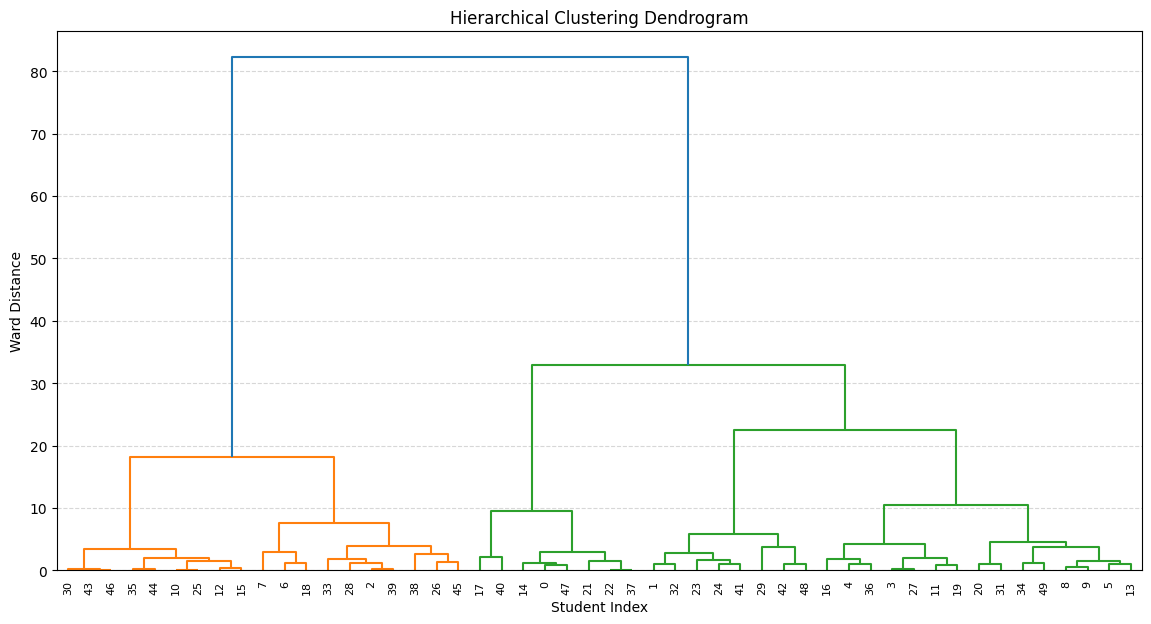

In [18]:
plt.figure(figsize=(14, 7))

dendrogram(
    Z,
    labels=X_students.index,
    leaf_rotation=90,
    leaf_font_size=8
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Student Index')
plt.ylabel('Ward Distance')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()